# 🎬 Cinematch - Fase 1: Configuración de Carpetas, Entrenamiento y Evaluación del Modelo (IDL2)

En este cuaderno realizaremos la preparación del proyecto y el modelado predictivo con la data limpia de **Cinematch** (682 registros de películas):

1. Conexión a Google Drive y creación automática de la estructura de carpetas de software.
2. Sincronización inicial con nuestro repositorio en GitHub.
3. Carga y preparación del dataset depurado en el IDL1 (`data_limpia_peliculas_knime.tab`).
4. División de datos en Entrenamiento (80%) y Prueba (20%).
5. Entrenamiento de modelos Random Forest y cálculo de métricas cuantitativas (Exactitud, Precisión, Exhaustividad, F1-Score y MAE).
6. Análisis de Overfitting vs Underfitting mediante la variación del número de árboles (20, 50, 100 y 200).
7. Guardado del modelo entrenado (`.pkl`) y subida automática de resultados a GitHub.


**Objetivos principales de este cuaderno:**
1. Crear automáticamente la arquitectura de carpetas en Google Drive.
2. Cargar y depurar el dataset limpio de IDL1 (`data_limpia_peliculas_knime.tab`).
3. Dividir los datos en conjuntos de Entrenamiento (80%) y Prueba (20%).
4. Entrenar un modelo de **Random Forest Classifier** regularizado para evitar el sobreajuste (*Overfitting*).
5. Evaluar el desempeño mediante métricas cuantitativas (Exactitud, Precisión, Exhaustividad, F1-Score y MAE).
6. Analizar el comportamiento del error al variar la profundidad del árbol.
7. Exportar el modelo entrenado (`.pkl`) y sincronizar los avances en GitHub.

In [1]:
# ==============================================================================
# I. Conexión a Google Drive y Creación de la Estructura de Carpetas
# ==============================================================================

import os
from google.colab import drive

drive.mount('/content/drive')

ROOT_DIR = '/content/drive/MyDrive/Cinematch_IDL2_DS_IA'

subcarpetas = [
    'backend/models',
    'backend/api',
    'frontend/assets',
    'db',
    'docs/diagrams',
    'docs/metrics',
    'docs/report_drafts',
]

print('Creando estructura limpia de carpetas en Google Drive...')
for carpeta in subcarpetas:
  ruta_completa = os.path.join(ROOT_DIR, carpeta)
  os.makedirs(ruta_completa, exist_ok=True)
  print(f'   Carpeta lista: {carpeta}')

readme_contenido = """# Cinematch IDL2 - Sistema Inteligente de Clasificación de Películas

Proyecto desarrollado para la unidad didáctica Desarrollo de Soluciones con IA.

## Estructura de Carpetas
- `DATASET/`: Dataset depurado en IDL1 (682 registros).
- `notebooks/`: Cuadernos de experimentación y entrenamiento en Google Colab.
- `backend/`: Modelo entrenado (.pkl) y servicios API REST.
- `frontend/`: Aplicación web interactiva construida en Streamlit.
- `db/`: Base de datos SQLite y scripts de diseño (DER).
- `docs/`: Gráficos de evaluación de métricas y borradores del informe final.
"""

with open(os.path.join(ROOT_DIR, 'README.md'), 'w', encoding='utf-8') as f:
  f.write(readme_contenido)

with open(os.path.join(ROOT_DIR, '.gitignore'), 'w', encoding='utf-8') as f:
  f.write('__pycache__/\n*.pyc\n.DS_Store\n*.tmp\n')

print('\n Estructura de software generada con éxito!')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Creando estructura limpia de carpetas en Google Drive...
   Carpeta lista: backend/models
   Carpeta lista: backend/api
   Carpeta lista: frontend/assets
   Carpeta lista: db
   Carpeta lista: docs/diagrams
   Carpeta lista: docs/metrics
   Carpeta lista: docs/report_drafts

 Estructura de software generada con éxito!


### **Vincular el Proyecto con GitHub**
Configuramos las credenciales de Git y vinculamos nuestro espacio de trabajo con el repositorio remoto de GitHub (`Cinematch_IDL2_DS_IA-`). Esto garantiza el control de versiones y respalda los archivos de código, modelos y gráficos en la nube.

In [2]:
# ==============================================================================
# II. Configuración e Inicialización de Git
# ==============================================================================

import os
from google.colab import userdata

try:
  GITHUB_TOKEN = userdata.get('GITHUB_TOKEN')
except Exception:
  from getpass import getpass

  GITHUB_TOKEN = getpass('Ingresar GitHub Personal Access Token: ')

GITHUB_USER = 'Yaseli-M'
GITHUB_EMAIL = 'i2511821@continental.edu.pe'
GITHUB_REPO = 'Cinematch_IDL2_DS_IA-'

%cd /content/drive/MyDrive/Cinematch_IDL2_DS_IA

!git config --global user.name "{GITHUB_USER}"
!git config --global user.email "{GITHUB_EMAIL}"

!git init
!git branch -M main
!git add .
!git commit -m "Commit 1: Estructura inicial del proyecto Cinematch"

!git remote remove origin 2>/dev/null || true
!git remote add origin https://{GITHUB_TOKEN}@github.com/{GITHUB_USER}/{GITHUB_REPO}.git
!git push -u origin main --force

/content/drive/MyDrive/Cinematch_IDL2_DS_IA
hint: Using 'master' as the name for the initial branch. This default branch name
hint: is subject to change. To configure the initial branch name to use in all
hint: of your new repositories, which will suppress this warning, call:
hint: 
hint: 	git config --global init.defaultBranch <name>
hint: 
hint: Names commonly chosen instead of 'master' are 'main', 'trunk' and
hint: 'development'. The just-created branch can be renamed via this command:
hint: 
hint: 	git branch -m <name>
Initialized empty Git repository in /content/drive/MyDrive/Cinematch_IDL2_DS_IA/.git/
[main (root-commit) a3ddc68] Commit 1: Estructura inicial del proyecto Cinematch
 4 files changed, 699 insertions(+)
 create mode 100644 .gitignore
 create mode 100644 DATASET/data_limpia_peliculas_knime.tab
 create mode 100644 Notebooks/01_entrenamiento_y_evaluacion.ipynb
 create mode 100644 README.md
Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compressi

### **Carga del Dataset Limpio**

Cargamos el archivo `data_limpia_peliculas_knime.tab` almacenado en la carpeta `DATASET/`. Este archivo contiene las 682 películas procesadas durante el IDL1 con variables como género, duración, nivel de violencia, romance, animación, rating y fecha de estreno.



In [3]:
# ==============================================================================
# III. Carga y Exploración de Datos
# ==============================================================================

import pandas as pd
import numpy as np

# 1. Definir la ruta del dataset
data_path = os.path.join(ROOT_DIR, 'DATASET', 'data_limpia_peliculas_knime.tab')

# 2. Leer el archivo
try:
    df = pd.read_csv(data_path, sep='\t')
except Exception:
    df = pd.read_csv(data_path)

print(f"Dataset cargado correctamente. Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas.\n")

# 3. Mostrar primeras 5 filas
df.head()

Dataset cargado correctamente. Dimensiones: 682 filas x 10 columnas.



,Selected,genero,duracion,violencia,lenguaje_ofensivo,romance,animacion,rating,fecha_estreno,publico_objetivo
0,No,COMEDIA,84.0,SI,ALTO,SI,NO,G,1989-03-12,GENERAL
1,No,TERROR,107.0,NAN,BAJO,SI,SI,PG-13,1994-04-26,GENERAL
2,No,ACCION,84.0,NAN,BAJO,NO,SI,NC-17,1999-09-14,ADOLESCENTES
3,No,CIENCIA FICCION,148.0,SI,NAN,NO,NAN,PG,1992-10-25,FAMILIAR
4,No,ROMANCE,129.0,NO,NAN,NO,NAN,NC-17,1994-05-09,INFANTIL


### **División de Datos: Entrenamiento (80%) y Prueba (20%)**

Aplicamos el **Train/Test Split**.
- **80% para Entrenamiento (Train)**
- **20% para Prueba (Test)**

In [4]:
# ==============================================================================
# IV. Preprocesamiento y División Train / Test
# ==============================================================================

import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

df_prep = df.copy()

# 1. Normalizar equivalentes a texto nulo
df_prep = df_prep.replace(['NAN', '?', 'nan', 'NaN'], np.nan)

# 2. Descartar únicamente los registros donde falta la etiqueta objetivo
df_prep = df_prep.dropna(subset=['publico_objetivo']).copy()

# 3. Procesar fecha de estreno (extraer año) e imputar con la mediana
if 'fecha_estreno' in df_prep.columns:
  df_prep['anio_estreno'] = pd.to_datetime(
      df_prep['fecha_estreno'], errors='coerce'
  ).dt.year
  df_prep['anio_estreno'] = df_prep['anio_estreno'].fillna(
      df_prep['anio_estreno'].median()
  )

# 4. Convertir duración a numérico e imputar nulos con la mediana
if 'duracion' in df_prep.columns:
  df_prep['duracion'] = pd.to_numeric(df_prep['duracion'], errors='coerce')
  df_prep['duracion'] = df_prep['duracion'].fillna(df_prep['duracion'].median())

# 5. Separar características predictoras (X) y target (y)
cols_inutiles = [
    'Selected',
    'id',
    'titulo',
    'fecha_estreno',
    'publico_objetivo',
]
cols_a_borrar = [c for c in cols_inutiles if c in df_prep.columns]

X = df_prep.drop(columns=cols_a_borrar)
y = df_prep['publico_objetivo']

# 6. Imputar variables categóricas con la moda
for col in X.select_dtypes(include=['object']).columns:
  if X[col].isnull().sum() > 0:
    X[col] = X[col].fillna(X[col].mode()[0])

# 7. Codificación binaria (One-Hot Encoding) y codificación de la variable objetivo
X_encoded = pd.get_dummies(X, drop_first=True)
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# 8. División 80% Entrenamiento / 20% Prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print('     PREPROCESAMIENTO Y DIVISIÓN DE DATOS         ')
print('==================================================')
print(f' Muestra limpia para modelar: {X.shape[0]} películas (643 de 682).')
print(
    f' Clases reales del target ({len(label_encoder.classes_)}):'
    f' {list(label_encoder.classes_)}'
)
print(f' Datos de Entrenamiento (Train): {X_train.shape[0]} películas')
print(f' Datos de Prueba (Test):        {X_test.shape[0]} películas')

     PREPROCESAMIENTO Y DIVISIÓN DE DATOS         
 Muestra limpia para modelar: 643 películas (643 de 682).
 Clases reales del target (5): ['ADOLESCENTES', 'ADULTOS', 'FAMILIAR', 'GENERAL', 'INFANTIL']
 Datos de Entrenamiento (Train): 514 películas
 Datos de Prueba (Test):        129 películas


### **Entrenamiento del Modelo y Métricas de Rendimiento**

Métricas de clasificación:
- **Exactitud (Accuracy)**: Porcentaje general de aciertos en la categoría del público.
- **Precisión (Precision)** y **Exhaustividad (Recall)**: Calidad de la detección por clase.
- **F1-Score**: Promedio armónico entre Precisión y Exhaustividad.
- **MAE**: Error absoluto medio entre las etiquetas codificadas.

   RESULTADOS DE EVALUACIÓN DEL MODELO CINEMATCH  
Métrica de Clasificación  Valor Obtenido
    Exactitud (Accuracy)          0.2636
   Precisión (Precision)          0.2597
  Exhaustividad (Recall)          0.2636
                F1-Score          0.2507


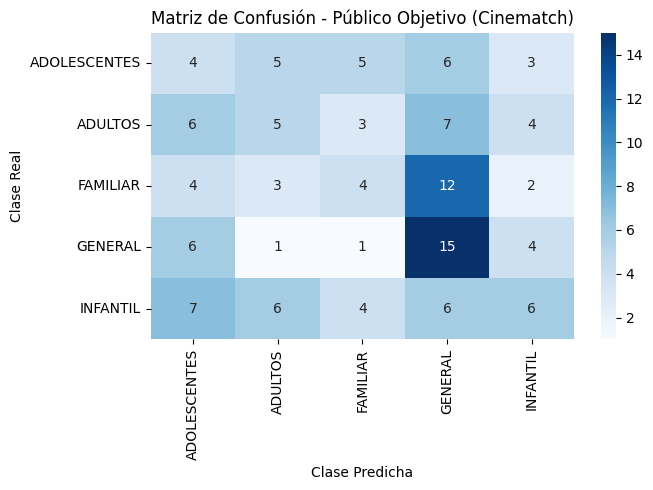

In [5]:
# ==============================================================================
# V. Entrenamiento del Modelo y Cálculo de Métricas de Clasificación
# ==============================================================================

import os
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# 1. Entrenar Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=10,
    random_state=42,
    class_weight='balanced',
)
modelo_rf.fit(X_train, y_train)

# 2. Generar predicciones
y_pred = modelo_rf.predict(X_test)

# 3. Métricas de Clasificación
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

# 4. Tabla de Métricas
tabla_metricas = pd.DataFrame({
    'Métrica de Clasificación': [
        'Exactitud (Accuracy)',
        'Precisión (Precision)',
        'Exhaustividad (Recall)',
        'F1-Score',
    ],
    'Valor Obtenido': [
        round(acc, 4),
        round(prec, 4),
        round(rec, 4),
        round(f1, 4),
    ],
})

print('   RESULTADOS DE EVALUACIÓN DEL MODELO CINEMATCH  ')
print('==================================================')
print(tabla_metricas.to_string(index=False))

# Guardar la tabla
tabla_metricas.to_csv(
    os.path.join(ROOT_DIR, 'docs/report_drafts', 'tabla_metricas_modelos.csv'),
    index=False,
)

# 5. Generar y guardar Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
)
plt.title('Matriz de Confusión - Público Objetivo (Cinematch)')
plt.xlabel('Clase Predicha')
plt.ylabel('Clase Real')
plt.tight_layout()
plt.savefig(
    os.path.join(ROOT_DIR, 'docs/metrics', 'matriz_confusion.png'), dpi=300
)
plt.show()

### **Experimento: Análisis de Overfitting vs Underfitting (Variación de Árboles)**

Variamos el número de estimadores/árboles en Random Forest (**20, 50, 100 y 200 árboles**) para observar cómo cambia el error entre Entrenamiento y Prueba, identificando el punto de ajuste óptimo.

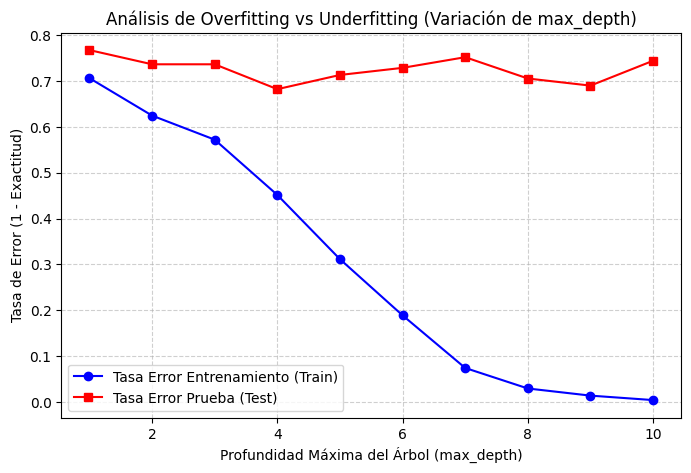

 Gráfico guardado exitosamente en: /content/drive/MyDrive/Cinematch_IDL2_DS_IA/docs/metrics/overfitting_vs_underfitting.png


In [6]:
# ==============================================================================
# VI. Experimento Overfitting vs Underfitting y Gráfica
# ==============================================================================

import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Rango de profundidades
profundidades = list(range(1, 11))
errores_train = []
errores_test = []

for depth in profundidades:
  model = RandomForestClassifier(
      n_estimators=100,
      max_depth=depth,
      random_state=42,
      class_weight='balanced',
  )
  model.fit(X_train, y_train)

  # Tasa de error = 1.0 - Accuracy
  err_tr = 1.0 - accuracy_score(y_train, model.predict(X_train))
  err_te = 1.0 - accuracy_score(y_test, model.predict(X_test))

  errores_train.append(err_tr)
  errores_test.append(err_te)

# 2. Graficar curvas de error (Train vs Test)
plt.figure(figsize=(8, 5))
plt.plot(
    profundidades,
    errores_train,
    label='Tasa Error Entrenamiento (Train)',
    marker='o',
    color='blue',
)
plt.plot(
    profundidades,
    errores_test,
    label='Tasa Error Prueba (Test)',
    marker='s',
    color='red',
)
plt.title('Análisis de Overfitting vs Underfitting (Variación de max_depth)')
plt.xlabel('Profundidad Máxima del Árbol (max_depth)')
plt.ylabel('Tasa de Error (1 - Exactitud)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

grafico_path = os.path.join(
    ROOT_DIR, 'docs/metrics', 'overfitting_vs_underfitting.png'
)
plt.savefig(grafico_path, dpi=300, bbox_inches='tight')
plt.show()

print(f' Gráfico guardado exitosamente en: {grafico_path}')

### **Guardado del Modelo Entrenado y Sincronización Final con GitHub**

Guardamos el modelo entrenado (`.pkl`) dentro de la carpeta `backend/models/`. Finalmente, guardamos todo (tablas, gráficos y modelo) en GitHub.

In [7]:
# ==============================================================================
# VII. Guardar Modelo (.pkl) y Actualizar GitHub
# ==============================================================================

import os
import joblib

# 1. Exportar el modelo entrenado y el encoder
modelo_export_path = os.path.join(
    ROOT_DIR, 'backend/models', 'modelo_cinematch.pkl'
)
encoder_export_path = os.path.join(
    ROOT_DIR, 'backend/models', 'label_encoder.pkl'
)

joblib.dump(modelo_rf, modelo_export_path)
joblib.dump(label_encoder, encoder_export_path)

print(f' Modelo exportado exitosamente en: {modelo_export_path}')
print(f' Encoder exportado exitosamente en: {encoder_export_path}')

# 2. Sincronizar todos los cambios con el repositorio de GitHub
%cd /content/drive/MyDrive/Cinematch_IDL2_DS_IA

!git add .
!git commit -m "Commit 2: Modelo regularizado, métricas de clasificación y gráficos actualizados"

!git remote remove origin 2>/dev/null || true
!git remote add origin https://{GITHUB_TOKEN}@github.com/Yaseli-M/Cinematch_IDL2_DS_IA-.git
!git push origin main --force

print(
    '\n Proyecto subido con éxito a repo de GitHub!'
)

 Modelo exportado exitosamente en: /content/drive/MyDrive/Cinematch_IDL2_DS_IA/backend/models/modelo_cinematch.pkl
 Encoder exportado exitosamente en: /content/drive/MyDrive/Cinematch_IDL2_DS_IA/backend/models/label_encoder.pkl
/content/drive/MyDrive/Cinematch_IDL2_DS_IA
[main 3356ba8] Commit 2: Modelo regularizado, métricas de clasificación y gráficos actualizados
 5 files changed, 5 insertions(+)
 create mode 100644 backend/models/label_encoder.pkl
 create mode 100644 backend/models/modelo_cinematch.pkl
 create mode 100644 docs/metrics/matriz_confusion.png
 create mode 100644 docs/metrics/overfitting_vs_underfitting.png
 create mode 100644 docs/report_drafts/tabla_metricas_modelos.csv
Enumerating objects: 13, done.
Counting objects: 100% (13/13), done.
Delta compression using up to 2 threads
Compressing objects: 100% (11/11), done.
Writing objects: 100% (12/12), 456.25 KiB | 11.13 MiB/s, done.
Total 12 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1),

In [8]:
# ==============================================================================
# VIII. Crear Archivo db/schema.sql e Inicializar la BD
# ==============================================================================

import sqlite3

# Ruta de tu proyecto
ROOT_DIR = '/content/drive/MyDrive/Cinematch_IDL2_DS_IA'
DB_DIR = os.path.join(ROOT_DIR, 'db')

# 1. Crear la carpeta 'db' si no existe
os.makedirs(DB_DIR, exist_ok=True)

# 2. Definir el texto con las tablas SQL
schema_sql = """-- Esquema de Base de Datos - Cinematch

CREATE TABLE IF NOT EXISTS usuarios (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    nombre TEXT NOT NULL,
    email TEXT UNIQUE NOT NULL,
    password_hash TEXT NOT NULL,
    rol TEXT NOT NULL DEFAULT 'usuario',
    fecha_registro TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS peliculas (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    titulo TEXT NOT NULL,
    genero TEXT NOT NULL,
    duracion INTEGER NOT NULL,
    violencia TEXT NOT NULL,
    lenguaje_ofensivo TEXT NOT NULL,
    romance TEXT NOT NULL,
    animacion TEXT NOT NULL,
    rating TEXT NOT NULL,
    anio_estreno INTEGER NOT NULL,
    publico_objetivo_real TEXT,
    fecha_registro TIMESTAMP DEFAULT CURRENT_TIMESTAMP
);

CREATE TABLE IF NOT EXISTS predicciones (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    usuario_id INTEGER,
    pelicula_id INTEGER,
    genero TEXT NOT NULL,
    duracion INTEGER NOT NULL,
    violencia TEXT NOT NULL,
    lenguaje_ofensivo TEXT NOT NULL,
    romance TEXT NOT NULL,
    animacion TEXT NOT NULL,
    rating TEXT NOT NULL,
    anio_estreno INTEGER NOT NULL,
    publico_objetivo_predicho TEXT NOT NULL,
    confianza REAL,
    fecha_prediccion TIMESTAMP DEFAULT CURRENT_TIMESTAMP,
    FOREIGN KEY (usuario_id) REFERENCES usuarios(id) ON DELETE SET NULL,
    FOREIGN KEY (pelicula_id) REFERENCES peliculas(id) ON DELETE SET NULL
);
"""

# 3. Escribir y guardar el archivo 'schema.sql'
schema_path = os.path.join(DB_DIR, 'schema.sql')
with open(schema_path, 'w', encoding='utf-8') as f:
  f.write(schema_sql)

print(f" Archivo 'schema.sql' generado exitosamente en: {schema_path}")

# 4. Crear el archivo binario de la base de datos 'cinematch.db'
db_path = os.path.join(DB_DIR, 'cinematch.db')
conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.executescript(schema_sql)

# Insertar un usuario administrador inicial
cursor.execute('SELECT COUNT(*) FROM usuarios')
if cursor.fetchone() == 0:
  cursor.execute(
      """
        INSERT INTO usuarios (nombre, email, password_hash, rol)
        VALUES ('Administrador Cinematch', 'admin@cinematch.com', 'pbkdf2:sha256:admin123', 'admin')
    """
  )

conn.commit()
conn.close()

print(f" Base de datos 'cinematch.db' inicializada en: {db_path}")

# 5. Sincronizar los nuevos archivos con GitHub
%cd /content/drive/MyDrive/Cinematch_IDL2_DS_IA
!git add .
!git commit -m "Commit 3: Esquema de base de datos SQLite (db/schema.sql)"
!git push origin main --force

print(
    '\n¡El archivo db/schema.sql y la base de datos ya están creados y'
    ' subidos a GitHub!'
)

 Archivo 'schema.sql' generado exitosamente en: /content/drive/MyDrive/Cinematch_IDL2_DS_IA/db/schema.sql
 Base de datos 'cinematch.db' inicializada en: /content/drive/MyDrive/Cinematch_IDL2_DS_IA/db/cinematch.db
/content/drive/MyDrive/Cinematch_IDL2_DS_IA
[main af04a3f] Commit 3: Esquema de base de datos SQLite (db/schema.sql)
 3 files changed, 45 insertions(+), 1 deletion(-)
 create mode 100644 db/cinematch.db
 create mode 100644 db/schema.sql
Enumerating objects: 10, done.
Counting objects: 100% (10/10), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 97.52 KiB | 6.96 MiB/s, done.
Total 7 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/Yaseli-M/Cinematch_IDL2_DS_IA-.git
   3356ba8..af04a3f  main -> main

¡El archivo db/schema.sql y la base de datos ya están creados y subidos a GitHub!


In [9]:
# ==============================================================================
# IX. Crear el Servidor API Backend y Actualizar GitHub
# ==============================================================================

import os

ROOT_DIR = '/content/drive/MyDrive/Cinematch_IDL2_DS_IA'
API_DIR = os.path.join(ROOT_DIR, 'backend/api')

os.makedirs(API_DIR, exist_ok=True)

# Código para la API
api_code = '''# ================================================================
# Servicio Backend API REST - Cinematch
# Ubicación: backend/api/main.py
# ==============================================================================

import os
import joblib
import pandas as pd
from flask import Flask, request, jsonify

app = Flask(__name__)

# Rutas absolutas del modelo y encoder
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(BASE_DIR, '../models/modelo_cinematch.pkl')
ENCODER_PATH = os.path.join(BASE_DIR, '../models/label_encoder.pkl')

# Cargar artefactos de IA al iniciar el servidor
modelo = None
label_encoder = None

try:
    modelo = joblib.load(MODEL_PATH)
    label_encoder = joblib.load(ENCODER_PATH)
    print("✓ Modelo y Encoder cargados exitosamente en la API.")
except Exception as e:
    print(f" Error al cargar artefactos de IA: {e}")

@app.route('/', methods=['GET'])
def home():
    return jsonify({
        "sistema": "Cinematch API REST",
        "estado": "Activo",
        "version": "1.0.0"
    })

@app.route('/predict', methods=['POST'])
def predict():
    if not modelo or not label_encoder:
        return jsonify({"error": "El modelo no está disponible en el servidor"}), 500

    try:
        data = request.get_json()

        # Estructurar características para el modelo
        df_input = pd.DataFrame([{
            'duracion': float(data.get('duracion', 100)),
            'anio_estreno': int(data.get('anio_estreno', 2024)),
            'genero': data.get('genero', 'COMEDIA'),
            'violencia': data.get('violencia', 'NO'),
            'lenguaje_ofensivo': data.get('lenguaje_ofensivo', 'BAJO'),
            'romance': data.get('romance', 'NO'),
            'animacion': data.get('animacion', 'NO'),
            'rating': data.get('rating', 'PG')
        }])

        # Aplicar One-Hot Encoding compatible
        df_encoded = pd.get_dummies(df_input)

        # Alinear columnas con el dataset de entrenamiento
        for col in modelo.feature_names_in_:
            if col not in df_encoded.columns:
                df_encoded[col] = 0
        df_encoded = df_encoded[modelo.feature_names_in_]

        # Realizar la predicción
        pred_idx = modelo.predict(df_encoded)[0]
        publico_predicho = label_encoder.inverse_transform([pred_idx])[0]

        return jsonify({
            "pelicula": data.get("titulo", "Sin título"),
            "publico_objetivo_predicho": publico_predicho,
            "estado_prediccion": "Exitoso"
        })

    except Exception as e:
        return jsonify({"error": f"Fallo en la inferencia: {str(e)}"}), 400

if __name__ == '__main__':
    app.run(host='0.0.0.0', port=5000, debug=True)
'''

# Escribir el archivo físico backend/api/main.py
api_file_path = os.path.join(API_DIR, 'main.py')
with open(api_file_path, 'w', encoding='utf-8') as f:
  f.write(api_code)

print(f" Archivo 'backend/api/main.py' generado con éxito en: {api_file_path}")

# Sincronizar con GitHub
%cd /content/drive/MyDrive/Cinematch_IDL2_DS_IA
!git add .
!git commit -m "Commit 4: Implementación del servicio Backend API REST (backend/api/main.py)"
!git push origin main --force

print('\n El módulo Backend API ha sido creado y sincronizado con GitHub')

 Archivo 'backend/api/main.py' generado con éxito en: /content/drive/MyDrive/Cinematch_IDL2_DS_IA/backend/api/main.py
/content/drive/MyDrive/Cinematch_IDL2_DS_IA
[main 9617be6] Commit 4: Implementación del servicio Backend API REST (backend/api/main.py)
 2 files changed, 81 insertions(+), 1 deletion(-)
 create mode 100644 backend/api/main.py
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (7/7), 3.54 KiB | 329.00 KiB/s, done.
Total 7 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/Yaseli-M/Cinematch_IDL2_DS_IA-.git
   af04a3f..9617be6  main -> main

 El módulo Backend API ha sido creado y sincronizado con GitHub


In [10]:
# ==============================================================================
# X. Crear la Interfaz Frontend Web (frontend/app.py) y Sincronizar con GitHub
# ==============================================================================

ROOT_DIR = '/content/drive/MyDrive/Cinematch_IDL2_DS_IA'
FRONTEND_DIR = os.path.join(ROOT_DIR, 'frontend')

os.makedirs(FRONTEND_DIR, exist_ok=True)

app_code = """# ==============================================================================
# Cinematch - Portal de Clasificación Cinematográfica (UI Premium)
# Ubicación: frontend/app.py
# ==============================================================================

import os
import joblib
import pandas as pd
import streamlit as st

# 1. Configuración del Portal Web
st.set_page_config(
    page_title="Cinematch | Clasificación Cinematográfica",
    page_icon="🍿",
    layout="centered"
)

# 2. Estilos CSS Personalizados (Fondo Oscuro Degradado e Ícono Gigante)
custom_styles = '''
    <style>
    /* Ocultar elementos nativos del entorno */
    #MainMenu {visibility: hidden;}
    footer {visibility: hidden;}
    header {visibility: hidden;}

    /* Fondo degradado oscuro estilo cine */
    .stApp {
        background: linear-gradient(135deg, #0d0b18 0%, #140f2d 50%, #080612 100%) !important;
        color: #ffffff !important;
    }

    /* Color de texto blanco para títulos y etiquetas */
    h1, h2, h3, h4, p, label, .stMarkdown {
        color: #ffffff !important;
    }

    /* Botón de acción estilo Netflix */
    .stButton>button {
        background-color: #E50914 !important;
        color: white !important;
        font-weight: bold !important;
        font-size: 1.15rem !important;
        border-radius: 8px !important;
        border: none !important;
        padding: 0.75rem 1rem !important;
        width: 100% !important;
        box-shadow: 0 4px 15px rgba(229, 9, 20, 0.4);
        transition: all 0.3s ease;
    }
    .stButton>button:hover {
        background-color: #B81D24 !important;
        box-shadow: 0 6px 20px rgba(229, 9, 20, 0.7);
        transform: translateY(-2px);
    }

    /* Cajas de selección e input oscuras */
    div[data-baseweb="input"], div[data-baseweb="select"] {
        background-color: #1a1636 !important;
        border-radius: 8px !important;
    }
    </style>
'''
st.markdown(custom_styles, unsafe_allow_html=True)

# 3. Encabezado con Ícono Gigante de Palomitas de Maíz
header_html = '''
    <div style="text-align: center; padding-top: 10px; padding-bottom: 20px;">
        <span style="font-size: 5rem; display: block; line-height: 1; margin-bottom: 5px;">🍿</span>
        <h1 style="font-size: 2.8rem; margin: 0; font-weight: 800; letter-spacing: -1px; color: #ffffff;">Cinematch</h1>
        <p style="font-size: 1.1rem; color: #b0b0d0; margin-top: 5px;">Consultoría de Clasificación Cinematográfica</p>
    </div>
'''
st.markdown(header_html, unsafe_allow_html=True)

st.markdown("---")

# 4. Carga interna de recursos de IA
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(BASE_DIR, '../backend/models/modelo_cinematch.pkl')
ENCODER_PATH = os.path.join(BASE_DIR, '../backend/models/label_encoder.pkl')

@st.cache_resource
def cargar_recursos():
    try:
        mod = joblib.load(MODEL_PATH)
        enc = joblib.load(ENCODER_PATH)
        return mod, enc
    except Exception:
        return None, None

modelo, label_encoder = cargar_recursos()

# 5. Formulario Limpio e Intuitivo
st.markdown("#### 📋 Ficha Técnica de la Producción")

titulo = st.text_input("Título de la película", value="Ej. El Viaje Fantástico")

col1, col2 = st.columns(2)

with col1:
    genero = st.selectbox("Género principal", ['ACCION', 'ANIMACION', 'AVENTURA', 'CIENCIA FICCION', 'COMEDIA', 'DRAMA', 'ROMANCE', 'TERROR'])
    duracion = st.number_input("Duración en minutos", min_value=30, max_value=300, value=105, step=5)
    violencia = st.selectbox("¿Contenido con violencia?", ['NO', 'SI'])
    lenguaje = st.selectbox("Lenguaje sensible", ['NINGUNO', 'BAJO', 'MEDIO', 'ALTO'])

with col2:
    rating = st.selectbox("Rating de referencia", ['G', 'PG', 'PG-13', 'R', 'NC-17'])
    anio = st.number_input("Año de estreno", min_value=1950, max_value=2030, value=2024, step=1)
    romance = st.selectbox("¿Contenido romántico?", ['NO', 'SI'])
    animacion = st.selectbox("¿Formato animado?", ['NO', 'SI'])

st.markdown("<br>", unsafe_allow_html=True)

# 6. Acción y Resultado Visual
if st.button("✨ Consultar Clasificación de Audiencia"):
    if modelo is not None and label_encoder is not None:
        input_data = pd.DataFrame([{
            'duracion': float(duracion),
            'anio_estreno': int(anio),
            'genero': genero,
            'violencia': violencia,
            'lenguaje_ofensivo': lenguaje,
            'romance': romance,
            'animacion': animacion,
            'rating': rating
        }])

        df_encoded = pd.get_dummies(input_data)
        for col in modelo.feature_names_in_:
            if col not in df_encoded.columns:
                df_encoded[col] = 0
        df_encoded = df_encoded[modelo.feature_names_in_]

        pred_idx = modelo.predict(df_encoded)
        clase_predicha = label_encoder.inverse_transform([pred_idx])

        st.success(f"### 🎯 Audiencia Sugerida: **{clase_predicha[0]}**")
        st.markdown(f"**Película:** {titulo} | **Género:** {genero} | **Duración:** {duracion} min.")
    else:
        st.error("Servicio no disponible en este momento. Intente más tarde.")
"""

# Escribir el archivo frontend/app.py
app_file_path = os.path.join(FRONTEND_DIR, 'app.py')
with open(app_file_path, 'w', encoding='utf-8') as f:
  f.write(app_code)

print(f" Archivo 'frontend/app.py' actualizado con éxito en: {app_file_path}")

# Sincronizar con GitHub
%cd /content/drive/MyDrive/Cinematch_IDL2_DS_IA
!git add .
!git commit -m "Commit 5: Interfaz web actualizada (frontend/app.py)"
!git push origin main --force

print(f" ")

IndentationError: unexpected indent (1665617104.py, line 76)